# BTC/USDT 30-Minute Direction Prediction

Predict whether the **next bar's open price** will be higher or lower than the
**current bar's open price**, and by how many percent, using a LightGBM model
trained on engineered technical features from the 30-minute BTC/USDT bar data.

**Target**
- `y_cls`: 1 if `open[t+1] > open[t]`, else 0 (binary direction)
- `y_reg`: `(open[t+1] - open[t]) / open[t] * 100` (signed percent move)

**Leakage guard**: since `open[t+1]` is essentially the current bar's close,
the target for row `t` is driven by bar `t`'s own price action. All features
used to predict it are therefore built from data available **through bar
`t-1`** only (the feature matrix is shifted forward by one bar relative to
the target) — no information from bar `t` or later ever reaches the model.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error, mean_squared_error,
)

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [ ]:
dataset = pd.read_csv("./data/processed_dataset_target_lag1.csv", index_col=0)
feature_cols = [col for col in dataset.columns if col not in ("y_reg")]


In [45]:
dataset["y_cls"] = (dataset["y_reg"] > 0).astype(int)

## 4. Time-based train / validation / test split

Chronological split (no shuffling) — 70% train / 15% validation / 15% test —
since shuffling would leak future information into training for a time series.

In [46]:
X = dataset[feature_cols]
y_cls = dataset["y_cls"]
y_reg = dataset["y_reg"]

n = len(dataset)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
yc_train, yc_val, yc_test = y_cls.iloc[:train_end], y_cls.iloc[train_end:val_end], y_cls.iloc[val_end:]
yr_train, yr_val, yr_test = y_reg.iloc[:train_end], y_reg.iloc[train_end:val_end], y_reg.iloc[val_end:]

print("train:", X_train.shape, dataset.index[0], "->", dataset.index[train_end - 1])
print("val:  ", X_val.shape, dataset.index[train_end], "->", dataset.index[val_end - 1])
print("test: ", X_test.shape, dataset.index[val_end], "->", dataset.index[-1])

train: (36684, 72) 2023-09-06 04:00:00+00:00 -> 2025-10-09 09:30:00+00:00
val:   (7861, 72) 2025-10-09 10:00:00+00:00 -> 2026-03-22 04:00:00+00:00
test:  (7862, 72) 2026-03-22 04:30:00+00:00 -> 2026-09-01 23:00:00+00:00


## 5. Hyperparameter search (walk-forward cross-validation)

Rather than trust a single train/val/test split, hyperparameters are selected
by average AUC across 5 expanding-window folds (`TimeSeriesSplit`), which
also gives a robustness check on how stable the edge is over time.

In [47]:
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb
from sklearn.metrics import roc_auc_score  

tscv = TimeSeriesSplit(n_splits=5)
candidates = [
    dict(learning_rate=0.01, num_leaves=15, colsample_bytree=0.7),
    dict(learning_rate=0.01, num_leaves=31, colsample_bytree=0.8),
    dict(learning_rate=0.03, num_leaves=15, colsample_bytree=0.7),
    dict(learning_rate=0.03, num_leaves=31, colsample_bytree=0.8),
]

Xv = X.values
yv = y_cls.values

cv_results = []
for cand in candidates:
    fold_aucs = []
    for train_idx, test_idx in tscv.split(Xv):
        cut = int(len(train_idx) * 0.85)
        tr_idx, va_idx = train_idx[:cut], train_idx[cut:]
        m = lgb.LGBMClassifier(
            n_estimators=2000, min_child_samples=50, subsample=0.8, subsample_freq=1,
            reg_alpha=0.1, reg_lambda=0.1, objective="binary",
            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **cand,
        )
        m.fit(
            Xv[tr_idx], yv[tr_idx],
            eval_set=[(Xv[va_idx], yv[va_idx])], eval_metric="auc",
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
        )
        p = m.predict_proba(Xv[test_idx])[:, 1]
        fold_aucs.append(roc_auc_score(yv[test_idx], p))
    cv_results.append((cand, np.mean(fold_aucs), np.std(fold_aucs), fold_aucs))
    print(cand, "mean AUC:", round(np.mean(fold_aucs), 4), "std:", round(np.std(fold_aucs), 4))

best_params, best_mean_auc, *_ = max(cv_results, key=lambda r: r[1])
print("\nBest config:", best_params, "mean walk-forward AUC:", round(best_mean_auc, 4))

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.01, 'num_leaves': 15, 'colsample_bytree': 0.7} mean AUC: 0.5414 std: 0.0079


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.01, 'num_leaves': 31, 'colsample_bytree': 0.8} mean AUC: 0.5416 std: 0.0064


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.03, 'num_leaves': 15, 'colsample_bytree': 0.7} mean AUC: 0.5402 std: 0.0068


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.03, 'num_leaves': 31, 'colsample_bytree': 0.8} mean AUC: 0.539 std: 0.0073

Best config: {'learning_rate': 0.01, 'num_leaves': 31, 'colsample_bytree': 0.8} mean walk-forward AUC: 0.5416


## 6. Final classifier: train and evaluate on held-out test set

In [48]:
clf = lgb.LGBMClassifier(
    n_estimators=3000, min_child_samples=50, subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1, objective="binary",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_params,
)
clf.fit(
    X_train, yc_train,
    eval_set=[(X_val, yc_val)], eval_metric="auc",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)
print("best_iteration:", clf.best_iteration_)

proba_val = clf.predict_proba(X_val)[:, 1]
proba_test = clf.predict_proba(X_test)[:, 1]

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best_iteration: 55


In [49]:
def report(y_true, proba, threshold, label):
    pred = (proba > threshold).astype(int)
    auc = roc_auc_score(y_true, proba)
    prec = precision_score(y_true, pred)
    rec = recall_score(y_true, pred)
    f1 = f1_score(y_true, pred)
    print(f"=== {label} (threshold={threshold:.3f}) ===")
    print(f"AUC:       {auc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1:        {f1:.4f}")
    print("Confusion matrix (rows=true, cols=pred):")
    print(confusion_matrix(y_true, pred))
    print(classification_report(y_true, pred, digits=4))
    return auc, prec, rec, f1


baseline_pred = np.ones(len(yc_test))
print("Baseline (always predict UP) accuracy:", (baseline_pred == yc_test.values).mean())
print()

report(yc_test, proba_test, 0.5, "Test set @ default threshold")

Baseline (always predict UP) accuracy: 0.5006359704909692

=== Test set @ default threshold (threshold=0.500) ===
AUC:       0.5338
Precision: 0.5156
Recall:    0.6773
F1:        0.5855
Confusion matrix (rows=true, cols=pred):
[[1421 2505]
 [1270 2666]]
              precision    recall  f1-score   support

           0     0.5281    0.3619    0.4295      3926
           1     0.5156    0.6773    0.5855      3936

    accuracy                         0.5198      7862
   macro avg     0.5218    0.5196    0.5075      7862
weighted avg     0.5218    0.5198    0.5076      7862



(0.5338429065247734,
 0.5155675884741829,
 0.6773373983739838,
 0.5854836938618645)

### Threshold sweep

The probability output has limited separation given AUC ~0.53, so maximizing
F1 alone tends to degenerate toward "always predict up" (near-100% recall,
~50% precision — no better than the base rate). Sweeping the threshold shows
the real precision/recall trade-off: raising the cutoff buys higher precision
at the cost of covering far fewer bars.

In [50]:
rows = []
for t in np.arange(0.46, 0.54, 0.01):
    pred = (proba_test > t).astype(int)
    coverage = pred.mean()  # fraction of bars where the model calls "up"
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(yc_test, pred, zero_division=0),
        "recall": recall_score(yc_test, pred, zero_division=0),
        "f1": f1_score(yc_test, pred, zero_division=0),
        "coverage": coverage,
    })
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,coverage
0,0.46,0.5007,0.9992,0.6671,0.9991
1,0.47,0.5015,0.9931,0.6664,0.9915
2,0.48,0.5057,0.9647,0.6636,0.9550
3,0.49,0.5116,0.8554,0.6403,0.8371
4,0.50,0.5156,0.6773,0.5855,0.6577
5,0.51,0.5223,0.5109,0.5166,0.4897
6,0.52,0.5294,0.3336,0.4093,0.3154
7,0.53,0.5677,0.1535,0.2416,0.1353
8,0.54,0.5379,0.0198,0.0382,0.0184


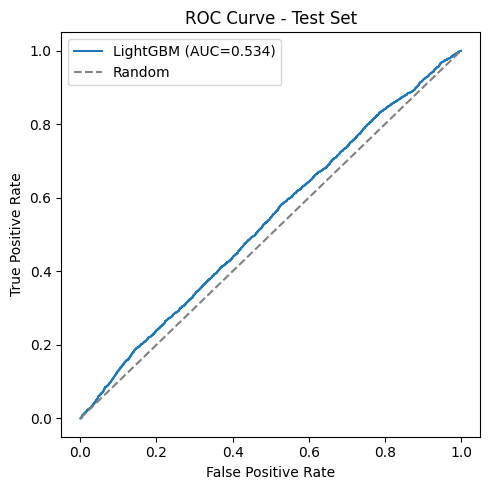

In [51]:
fpr, tpr, _ = roc_curve(yc_test, proba_test)
test_auc = roc_auc_score(yc_test, proba_test)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"LightGBM (AUC={test_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Test Set")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Feature importance

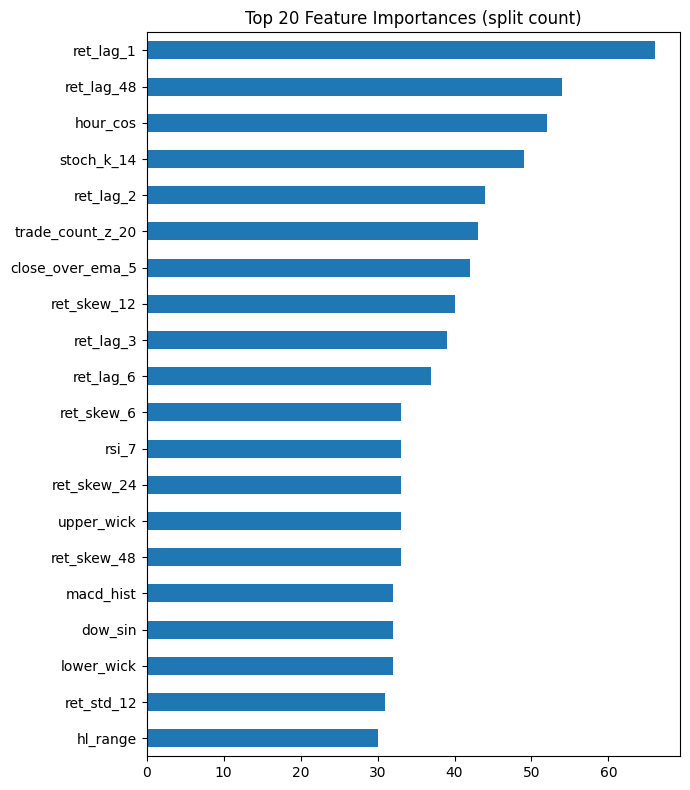

ret_lag_1           66
ret_lag_48          54
hour_cos            52
stoch_k_14          49
ret_lag_2           44
trade_count_z_20    43
close_over_ema_5    42
ret_skew_12         40
ret_lag_3           39
ret_lag_6           37
ret_skew_6          33
rsi_7               33
ret_skew_24         33
upper_wick          33
ret_skew_48         33
macd_hist           32
dow_sin             32
lower_wick          32
ret_std_12          31
hl_range            30
dtype: int32

In [52]:
importance = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(7, 8))
importance.head(20).iloc[::-1].plot(kind="barh")
plt.title("Top 20 Feature Importances (split count)")
plt.tight_layout()
plt.show()

importance.head(20)

## 8. Magnitude regression

A second LightGBM regressor predicts the signed percent move itself
(`y_reg`), so predictions can be reported as "up/down by X%" rather than
direction alone. Compared against a naive baseline that always predicts 0%.

In [53]:
reg = lgb.LGBMRegressor(
    n_estimators=3000, min_child_samples=50, subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1, objective="regression",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_params,
)
reg.fit(
    X_train, yr_train,
    eval_set=[(X_val, yr_val)], eval_metric="l2",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)

pred_reg = reg.predict(X_test)
mae = mean_absolute_error(yr_test, pred_reg)
rmse = mean_squared_error(yr_test, pred_reg) ** 0.5
naive_mae = mean_absolute_error(yr_test, np.zeros_like(yr_test))
dir_acc_from_reg = ((pred_reg > 0).astype(int) == yc_test.values).mean()

print(f"MAE:  {mae:.4f}%")
print(f"RMSE: {rmse:.4f}%")
print(f"Naive (predict 0%) MAE: {naive_mae:.4f}%")
print(f"Direction accuracy implied by regressor sign: {dir_acc_from_reg:.4f}")

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE:  0.1928%
RMSE: 0.2986%
Naive (predict 0%) MAE: 0.1927%
Direction accuracy implied by regressor sign: 0.4991


In [54]:
pred_df = pd.DataFrame({
    "y_true": yr_test,
    "y_pred": pred_reg,
    "y_cls_true": yc_test,
    "y_cls_pred": (pred_reg > 0).astype(int),
})

In [55]:
pred_df.sort_values("y_true", ascending=False).head(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-08-19 15:00:00+00:00,3.593499,0.002817,1,1
2026-03-23 11:00:00+00:00,3.138626,0.004773,1,1
2026-08-21 08:30:00+00:00,2.612223,0.005714,1,1
2026-08-20 08:00:00+00:00,2.196159,-0.001815,1,0
2026-06-26 13:30:00+00:00,2.140514,0.008676,1,1
2026-06-07 22:00:00+00:00,1.969879,0.004773,1,1
2026-06-25 14:00:00+00:00,1.779773,0.040072,1,1
2026-04-07 23:00:00+00:00,1.732763,0.019518,1,1
2026-07-06 15:30:00+00:00,1.732166,0.003365,1,1


In [56]:
pred_df.sort_values("y_true", ascending=False).tail(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-04 10:00:00+00:00,-1.208390,0.027699,0,1
2026-06-24 13:00:00+00:00,-1.217871,0.004787,0,1
2026-06-04 00:00:00+00:00,-1.223427,0.044614,0,1
2026-04-08 13:30:00+00:00,-1.224840,-0.003474,0,0
2026-04-27 15:00:00+00:00,-1.233922,0.004894,0,1
2026-07-27 22:30:00+00:00,-1.254886,0.005012,0,1
2026-06-08 01:00:00+00:00,-1.263039,0.004577,0,1
2026-08-28 15:30:00+00:00,-1.264111,0.004758,0,1
2026-06-05 18:30:00+00:00,-1.266681,0.046478,0,1


In [40]:
pred_df.sort_values("y_pred", ascending=False).head(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-05 19:00:00+00:00,0.778302,0.084744,1,1
2026-06-03 00:30:00+00:00,0.242092,0.064764,1,1
2026-06-02 23:30:00+00:00,0.476868,0.060308,1,1
2026-06-02 23:00:00+00:00,0.088559,0.057879,1,1
2026-06-05 14:30:00+00:00,0.785484,0.057305,1,1
2026-06-03 23:30:00+00:00,-0.562201,0.053591,0,1
2026-06-04 01:30:00+00:00,-0.832376,0.053562,0,1
2026-06-17 19:30:00+00:00,-0.260819,0.049325,0,1
2026-06-04 02:00:00+00:00,1.318583,0.049280,1,1


In [41]:
pred_df.sort_values("y_pred", ascending=False).tail(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-25 16:00:00+00:00,0.310622,-0.014945,1,0
2026-06-30 14:00:00+00:00,0.515568,-0.015361,1,0
2026-07-07 15:00:00+00:00,0.298858,-0.016132,1,0
2026-07-17 14:00:00+00:00,0.140434,-0.016395,1,0
2026-06-18 17:30:00+00:00,0.036703,-0.016415,1,0
2026-08-21 06:00:00+00:00,-0.173215,-0.016433,0,0
2026-06-17 18:30:00+00:00,0.171044,-0.016510,1,0
2026-04-02 01:30:00+00:00,-0.336604,-0.016549,0,0
2026-08-20 11:00:00+00:00,-0.135841,-0.016783,0,0


## 9. Combined prediction example

For the most recent bar in the test set, combine the classifier's direction
probability with the regressor's magnitude estimate into a single readable
forecast.

In [29]:
last_ts = X_test.index[-1]
p_up = clf.predict_proba(X_test.loc[[last_ts]])[0, 1]
pct_move = reg.predict(X_test.loc[[last_ts]])[0]

direction = "UP" if p_up > 0.5 else "DOWN"
print(f"As of {last_ts}: predicted next-bar direction = {direction} "
      f"(P(up)={p_up:.3f}), predicted magnitude = {pct_move:+.3f}%")

As of 2026-09-01 23:00:00+00:00: predicted next-bar direction = UP (P(up)=0.523), predicted magnitude = +0.005%


## 10. Discussion

- The 30-minute BTC/USDT direction task is close to an efficient-market null:
  test-set AUC lands modestly above 0.50 (~0.534), and this is confirmed by
  the walk-forward cross-validation (AUC consistently in the ~0.53-0.55
  range across 5 non-overlapping expanding folds, not just a lucky single
  split).
- The threshold sweep shows a real, if modest, precision/recall trade-off:
  at the default 0.5 cutoff the model is right ~52% of the time on ~66% of
  bars, and raising the cutoff to ~0.52-0.53 lifts precision toward
  ~53-57% while only firing on the 13-32% of bars it is most confident
  about. Beyond that, coverage shrinks to a handful of bars and the
  precision estimate becomes noisy (small-sample) rather than continuing to
  improve — a direct symptom of how little separable signal is actually
  present at this horizon.
- The magnitude regressor's MAE is barely better than always predicting 0%,
  and its implied directional accuracy is close to random — predicting the
  *size* of a 30-minute move is much harder than predicting its *sign*, since
  bar-to-bar returns are close to i.i.d. noise dominated by microstructure.
- Feature importances are dominated by short-lag returns, the stochastic
  oscillator, cyclical hour-of-day, and volume/trade-count anomalies —
  consistent with short-term mean-reversion/momentum and session-driven
  liquidity effects rather than any single dominant indicator.